<a href="https://colab.research.google.com/github/maliksonmez/arnavutkoy-air-quality-forecast/blob/main/notebooks/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Analiz araçları hazır.")

Analiz araçları hazır.


In [ ]:
from google.colab import files
yuklenen = files.upload()

Saving İstanbul - Arnavutköy_16.09.2023-16.09.2026_Hava Kalitesi - İstasyon Veri İndirme_Detay.xlsx to İstanbul - Arnavutköy_16.09.2023-16.09.2026_Hava Kalitesi - İstasyon Veri İndirme_Detay.xlsx


In [ ]:
dosya_adi = next(iter(yuklenen))

ham_veri = pd.read_excel(dosya_adi, header=None)

print("Satır ve sütun sayısı:", ham_veri.shape)
display(ham_veri.head(8))

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Satır ve sütun sayısı: (26307, 5)


,0,1,2,3,4
0,Tarih,İstanbul - Arnavutköy,NaN,NaN,NaN
1,NaN,PM10 ( µg/m3 ),PM 2.5 ( µg/m3 ),SO2 ( µg/m3 ),NO2 ( µg/m3 )
2,2023-09-16 00:00:56,"985,00","20,00","1,80","39,90"
3,2023-09-16 01:00:56,"33,00","20,00","1,80","41,90"
4,2023-09-16 02:00:56,"26,20","20,00","2,40","28,90"
5,2023-09-16 03:00:56,"14,40","21,00","2,60","47,70"
6,2023-09-16 04:00:56,"24,70","22,90","2,20","27,80"
7,2023-09-16 05:00:56,"12,40","14,30","2,30","34,00"


In [ ]:
# Orijinal tabloyu koruyup bir kopya üzerinde çalışıyoruz.
veri = ham_veri.iloc[2:].copy()

veri.columns = ["tarih", "PM10", "PM2_5", "SO2", "NO2"]
veri = veri.reset_index(drop=True)

# Tarihleri tarih-saat biçimine çeviriyoruz.
veri["tarih"] = pd.to_datetime(veri["tarih"], errors="coerce")

# Virgüllü metinleri sayıya, "-" işaretlerini eksik değere çeviriyoruz.
kirleticiler = ["PM10", "PM2_5", "SO2", "NO2"]

for sutun in kirleticiler:
    metin = veri[sutun].astype("string").str.strip()
    metin = metin.str.replace(",", ".", regex=False)
    veri[sutun] = pd.to_numeric(metin, errors="coerce")

veri = veri.sort_values("tarih").reset_index(drop=True)

display(veri.head())
veri.info()

,tarih,PM10,PM2_5,SO2,NO2
0,2023-09-16 00:00:56,985.0,20.0,1.8,39.9
1,2023-09-16 01:00:56,33.0,20.0,1.8,41.9
2,2023-09-16 02:00:56,26.2,20.0,2.4,28.9
3,2023-09-16 03:00:56,14.4,21.0,2.6,47.7
4,2023-09-16 04:00:56,24.7,22.9,2.2,27.8


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26305 entries, 0 to 26304
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   tarih   26305 non-null  datetime64[ns]
 1   PM10    24955 non-null  Float64       
 2   PM2_5   24778 non-null  Float64       
 3   SO2     24978 non-null  Float64       
 4   NO2     25270 non-null  Float64       
dtypes: Float64(4), datetime64[ns](1)
memory usage: 1.1 MB


In [ ]:
# Her kirleticide kaç ölçüm eksik?
eksik_ozeti = pd.DataFrame({
    "Dolu ölçüm": veri[kirleticiler].notna().sum(),
    "Eksik ölçüm": veri[kirleticiler].isna().sum(),
    "Eksik oranı (%)": (
        veri[kirleticiler].isna().mean() * 100
    ).round(2)
})

display(eksik_ozeti)

# Tarih ve saat kontrolleri
print("Başlangıç:", veri["tarih"].min())
print("Bitiş:", veri["tarih"].max())
print("Eksik/geçersiz tarih:", veri["tarih"].isna().sum())
print("Tekrarlı tarih-saat:", veri["tarih"].duplicated().sum())

print("\nArdışık kayıtlar arasındaki süreler:")
display(veri["tarih"].diff().value_counts())

,Dolu ölçüm,Eksik ölçüm,Eksik oranı (%)
PM10,24955,1350,5.13
PM2_5,24778,1527,5.80
SO2,24978,1327,5.04
NO2,25270,1035,3.93


Başlangıç: 2023-09-16 00:00:56
Bitiş: 2026-09-16 00:00:56
Eksik/geçersiz tarih: 0
Tekrarlı tarih-saat: 0

Ardışık kayıtlar arasındaki süreler:


,count
tarih,
0 days 01:00:00,26304


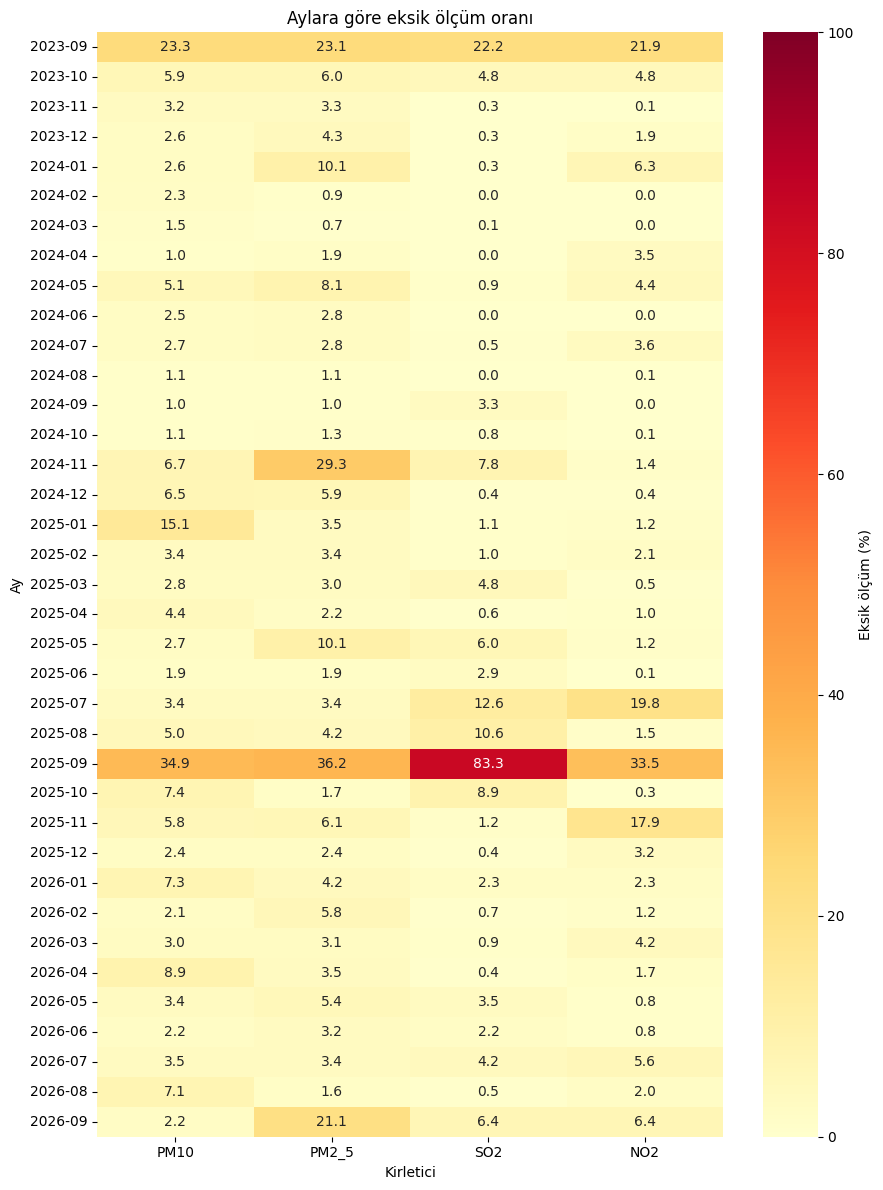

,Saat sayısı
Aynı saatte eksik kirletici sayısı,
0,22930
1,2461
2,429
3,20
4,465


In [ ]:
# Orijinal veriyi değiştirmeden tarih üzerinden çalışıyoruz.
zamanli_veri = veri.set_index("tarih")

# Her ay, her kirleticinin eksik ölçüm yüzdesi
aylik_eksik = (
    zamanli_veri[kirleticiler]
    .isna()
    .resample("MS")
    .mean()
    .mul(100)
)

# Grafikte ayları okunur biçimde gösteriyoruz.
grafik_verisi = aylik_eksik.copy()
grafik_verisi.index = grafik_verisi.index.strftime("%Y-%m")

plt.figure(figsize=(9, 12))
sns.heatmap(
    grafik_verisi,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Eksik ölçüm (%)"}
)

plt.title("Aylara göre eksik ölçüm oranı")
plt.xlabel("Kirletici")
plt.ylabel("Ay")
plt.tight_layout()
plt.show()

# Aynı saat içinde kaç kirleticinin ölçümü eksik?
eksik_sayisi = veri[kirleticiler].isna().sum(axis=1)

ortak_eksikler = (
    eksik_sayisi.value_counts()
    .reindex(range(5), fill_value=0)
    .sort_index()
    .rename_axis("Aynı saatte eksik kirletici sayısı")
    .to_frame("Saat sayısı")
)

display(ortak_eksikler)

In [ ]:
kesintiler = []

for kirletici in kirleticiler:
    eksik = veri[kirletici].isna()

    # Dolu/eksik durumu her değiştiğinde yeni grup oluştur.
    gruplar = eksik.ne(eksik.shift()).cumsum()

    for _, blok in veri.loc[eksik].groupby(gruplar[eksik]):
        kesintiler.append({
            "Kirletici": kirletici,
            "Başlangıç": blok["tarih"].iloc[0],
            "Son eksik saat": blok["tarih"].iloc[-1],
            "Eksik saat sayısı": len(blok)
        })

kesinti_tablosu = pd.DataFrame(kesintiler)

# Her kirleticinin en uzun üç kesintisi
en_uzun_kesintiler = (
    kesinti_tablosu
    .sort_values(
        ["Kirletici", "Eksik saat sayısı"],
        ascending=[True, False]
    )
    .groupby("Kirletici", sort=False)
    .head(3)
    .reset_index(drop=True)
)

display(en_uzun_kesintiler)

,Kirletici,Başlangıç,Son eksik saat,Eksik saat sayısı
0,NO2,2025-09-01 14:00:56,2025-09-09 12:00:56,191
1,NO2,2023-09-28 16:00:56,2023-10-02 11:00:56,92
2,NO2,2025-07-25 23:00:56,2025-07-28 15:00:56,65
3,PM10,2025-09-01 14:00:56,2025-09-09 14:00:56,193
4,PM10,2023-09-28 16:00:56,2023-10-02 13:00:56,94
5,PM10,2025-01-10 21:00:56,2025-01-13 12:00:56,64
6,PM2_5,2025-09-01 14:00:56,2025-09-09 14:00:56,193
7,PM2_5,2023-09-28 16:00:56,2023-10-02 13:00:56,94
8,PM2_5,2026-09-04 20:00:56,2026-09-07 14:00:56,67
9,SO2,2025-09-01 14:00:56,2025-09-10 08:00:56,211


In [ ]:
# Eksik değerler bu hesaplamalara dahil edilmez.
istatistikler = (
    veri[kirleticiler]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .round(2)
)

display(istatistikler)

# Sıfır ve negatif ölçümlerin sayısı
deger_kontrolu = pd.DataFrame({
    "Sıfır ölçüm": veri[kirleticiler].eq(0).sum(),
    "Negatif ölçüm": veri[kirleticiler].lt(0).sum()
})

display(deger_kontrolu)

,count,mean,std,min,25%,50%,75%,95%,99%,max
PM10,24955.0,27.46,23.92,0.0,14.0,21.9,33.9,67.9,106.8,985.0
PM2_5,24778.0,15.12,15.8,0.0,8.5,12.1,18.0,34.0,51.72,985.0
SO2,24978.0,5.5,4.42,0.1,2.7,4.3,7.4,13.9,17.2,281.2
NO2,25270.0,24.27,21.9,0.4,10.4,17.3,31.1,64.9,99.4,283.4


,Sıfır ölçüm,Negatif ölçüm
PM10,4,0
PM2_5,5,0
SO2,0,0
NO2,0,0


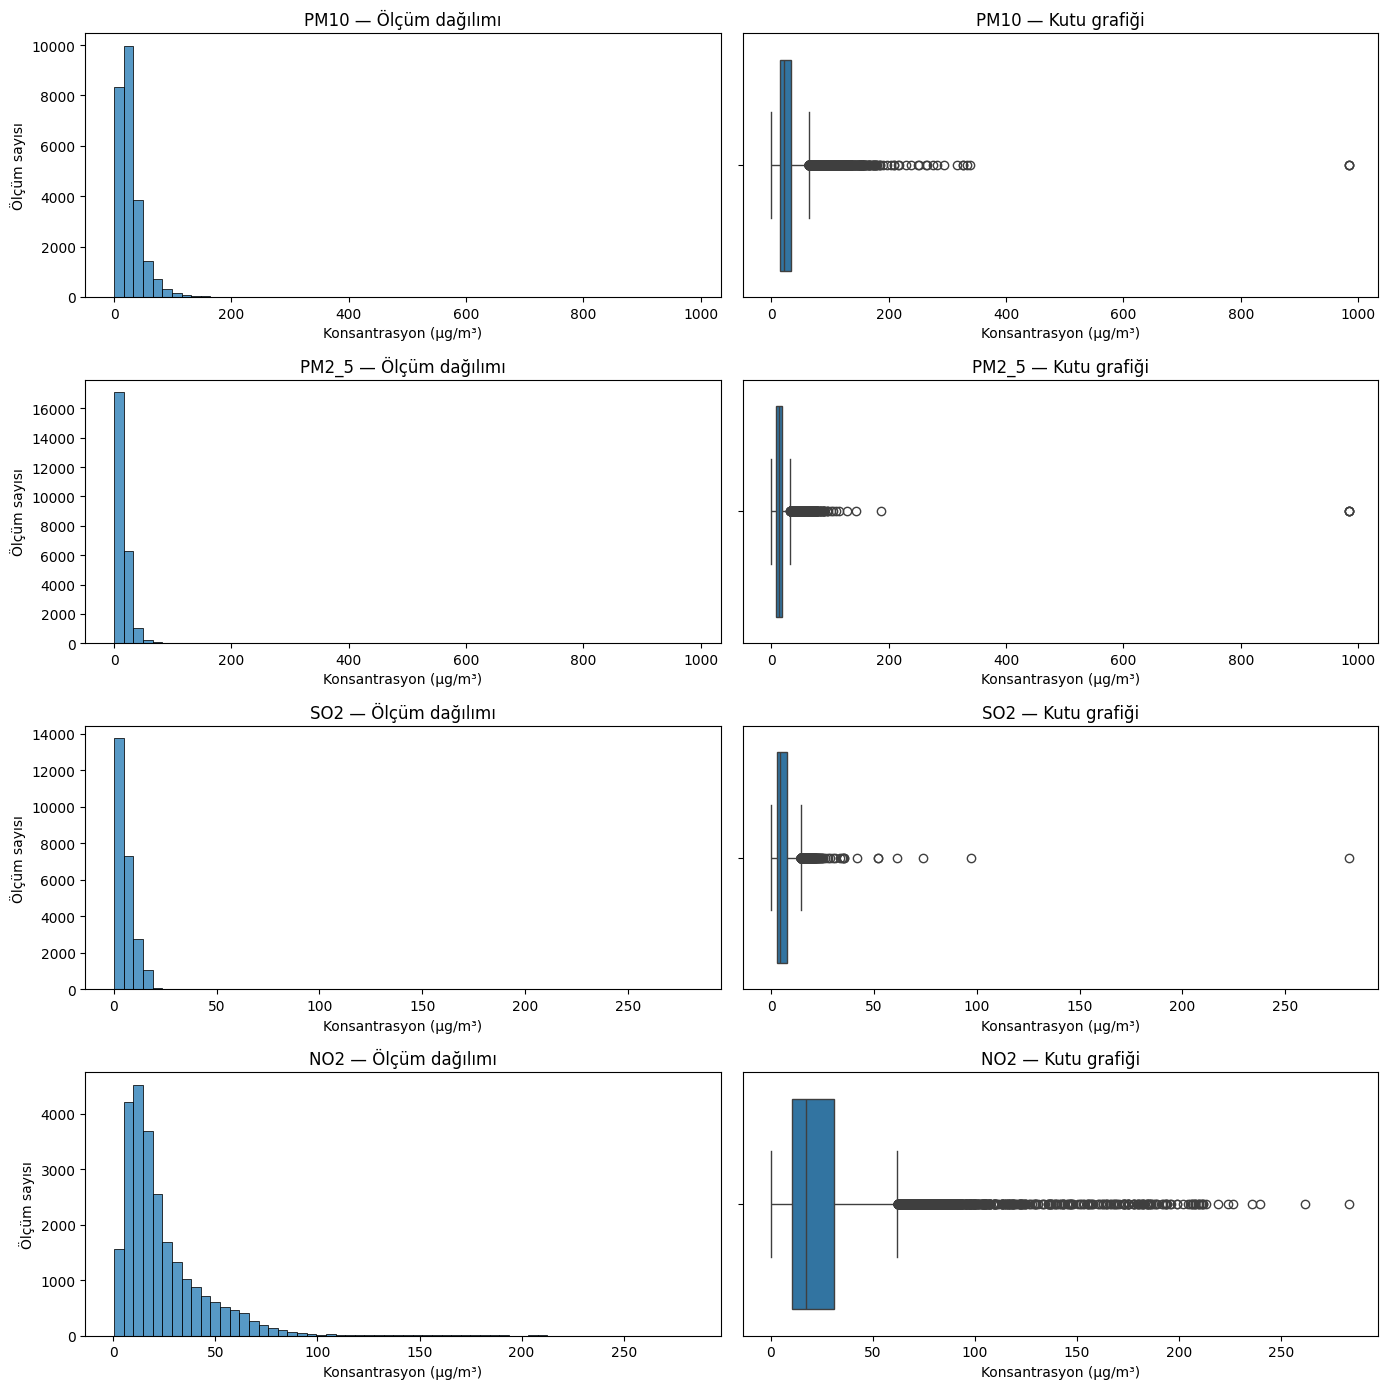

In [ ]:
fig, eksenler = plt.subplots(4, 2, figsize=(14, 14))

for i, kirletici in enumerate(kirleticiler):
    olcumler = veri[kirletici].dropna().astype(float)

    sns.histplot(
        x=olcumler,
        bins=60,
        ax=eksenler[i, 0]
    )
    eksenler[i, 0].set_title(f"{kirletici} — Ölçüm dağılımı")
    eksenler[i, 0].set_xlabel("Konsantrasyon (µg/m³)")
    eksenler[i, 0].set_ylabel("Ölçüm sayısı")

    sns.boxplot(
        x=olcumler,
        ax=eksenler[i, 1]
    )
    eksenler[i, 1].set_title(f"{kirletici} — Kutu grafiği")
    eksenler[i, 1].set_xlabel("Konsantrasyon (µg/m³)")

plt.tight_layout()
plt.show()


PM10 – en yüksek 10 değer ve kaç kez görüldükleri:


,count
PM10,
985.0,3
337.8,1
334.1,1
327.3,1
327.0,1
316.4,1
294.7,1
282.3,1
274.9,1



PM2_5 – en yüksek 10 değer ve kaç kez görüldükleri:


,count
PM2_5,
985.0,4
186.0,1
144.1,1
128.4,1
114.3,1
110.2,1
104.8,1
101.4,1
96.2,1



SO2 – en yüksek 10 değer ve kaç kez görüldükleri:


...

PM2.5 > PM10 olan saat: 3059 (dolu saatlerin %12.6'i)

Fark büyüklüğü (PM2.5 - PM10):


,0
count,3059.0
mean,4.57
std,35.54
min,0.1
25%,1.1
50%,2.6
75%,4.7
max,982.0



Aylara göre dağılım (belirli bir dönemde mi yoğunlaşıyor?):


,count
tarih,
2023-09,14
2023-10,49
2023-11,174
2023-12,162
2024-01,97
2024-02,78
2024-03,117
2024-04,77
2024-05,21


6+ saat aynı kalan blok sayısı: 0


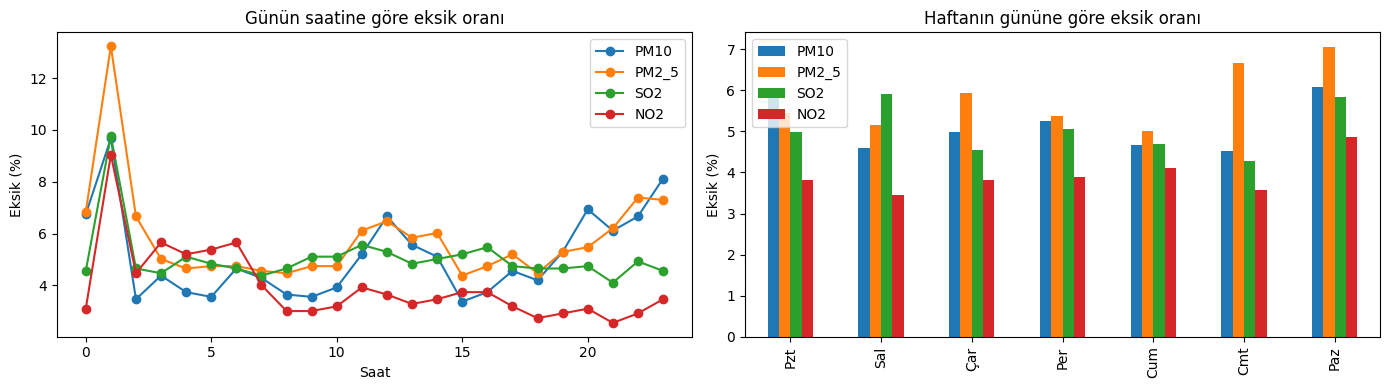

PM10: kesinti sonrası ilk ölçüm medyanı 19.0 (genel medyan 21.9), en yüksek 153.0, n=636
PM2_5: kesinti sonrası ilk ölçüm medyanı 12.5 (genel medyan 12.1), en yüksek 985.0, n=697
SO2: kesinti sonrası ilk ölçüm medyanı 1.0 (genel medyan 4.3), en yüksek 97.2, n=253
NO2: kesinti sonrası ilk ölçüm medyanı 12.4 (genel medyan 17.3), en yüksek 119.5, n=292


In [ ]:
# Arnavutköy – Şüpheli ve eksik verilerin sebep analizi
# Her "# %%" bloğu ayrı bir Colab hücresidir. Mevcut notebook'taki
# `veri`, `kirleticiler` değişkenlerini kullanır; notebook'un sonuna ekleyin.

# %% 1) En sık görülen değerler ve 985'ler
# Sensör hata kodları genelde "yuvarlak ve tekrar eden" sayılardır.
for k in kirleticiler:
    print(f"\n{k} – en yüksek 10 değer ve kaç kez görüldükleri:")
    display(veri[k].value_counts().sort_index(ascending=False).head(10))

supheli_985 = veri[(veri[kirleticiler] == 985).any(axis=1)]
print("985 içeren satır sayısı:", len(supheli_985))
display(supheli_985)

# %% 2) Şüpheli değerlerin çevresi: önceki ve sonraki 3 saat
# Bir kesintinin hemen sonrasına denk geliyorsa "cihaz yeniden başlarken" hatası olabilir.
for idx in supheli_985.index:
    print(f"\n--- Satır {idx} çevresi ---")
    display(veri.iloc[max(idx - 3, 0): idx + 4])

# %% 3) Ani sıçramalar (spike): değer, çevresindeki 24 saatin medyanının kaç katı?
# Gerçek kirlilik olayları birkaç saat sürer; tek saatlik dev sıçramalar ölçüm hatasına işaret eder.
sicramalar = []
for k in kirleticiler:
    medyan = veri[k].rolling(25, center=True, min_periods=12).median()
    oran = veri[k] / medyan
    tek_saatlik = (oran > 5) & (veri[k] > 100)
    for idx in veri.index[tek_saatlik]:
        sicramalar.append({
            "Kirletici": k,
            "Tarih": veri.at[idx, "tarih"],
            "Değer": veri.at[idx, k],
            "24s medyan": round(medyan[idx], 1),
            "Önceki saat": veri[k].get(idx - 1),
            "Sonraki saat": veri[k].get(idx + 1),
        })

sicrama_tablosu = pd.DataFrame(sicramalar)
print("Ani sıçrama sayısı:", len(sicrama_tablosu))
display(sicrama_tablosu.sort_values("Değer", ascending=False).head(30))

# %% 4) Fiziksel tutarlılık: PM2.5, PM10'un bir parçasıdır, ondan büyük olamaz
ikisi_dolu = veri[["PM10", "PM2_5"]].notna().all(axis=1)
tutarsiz = veri[ikisi_dolu & (veri["PM2_5"] > veri["PM10"])]

print(f"PM2.5 > PM10 olan saat: {len(tutarsiz)} "
      f"(dolu saatlerin %{len(tutarsiz) / ikisi_dolu.sum() * 100:.1f}'i)")
print("\nFark büyüklüğü (PM2.5 - PM10):")
display((tutarsiz["PM2_5"] - tutarsiz["PM10"]).describe().round(2))
print("\nAylara göre dağılım (belirli bir dönemde mi yoğunlaşıyor?):")
display(tutarsiz["tarih"].dt.to_period("M").value_counts().sort_index())

# %% 5) Donmuş sensör: aynı değerin saatlerce tekrar etmesi
# Gerçek ölçümler sürekli dalgalanır; 6+ saat birebir aynı değer genelde cihaz takılmasıdır.
donmalar = []
for k in kirleticiler:
    seri = veri[k]
    grup = seri.ne(seri.shift()).cumsum()
    for _, blok in veri.groupby(grup):
        if blok[k].notna().all() and len(blok) >= 6:
            donmalar.append({
                "Kirletici": k,
                "Değer": blok[k].iloc[0],
                "Başlangıç": blok["tarih"].iloc[0],
                "Saat sayısı": len(blok),
            })

donma_tablosu = pd.DataFrame(donmalar)
print("6+ saat aynı kalan blok sayısı:", len(donma_tablosu))
if len(donma_tablosu):
    display(donma_tablosu.sort_values("Saat sayısı", ascending=False).head(20))

# %% 6) Eksikler günün belirli saatlerinde / haftanın belirli günlerinde mi?
# Belirli bir saatte yoğunlaşıyorsa rutin bakım veya kalibrasyon olabilir.
eksik_bayrak = veri[kirleticiler].isna()
saat = veri["tarih"].dt.hour
gun = veri["tarih"].dt.dayofweek  # 0 = Pazartesi

fig, eksenler = plt.subplots(1, 2, figsize=(14, 4))
(eksik_bayrak.groupby(saat).mean() * 100).plot(ax=eksenler[0], marker="o")
eksenler[0].set_title("Günün saatine göre eksik oranı")
eksenler[0].set_xlabel("Saat")
eksenler[0].set_ylabel("Eksik (%)")

gun_adlari = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]
gunluk = eksik_bayrak.groupby(gun).mean() * 100
gunluk.index = gun_adlari
gunluk.plot(kind="bar", ax=eksenler[1])
eksenler[1].set_title("Haftanın gününe göre eksik oranı")
eksenler[1].set_ylabel("Eksik (%)")
plt.tight_layout()
plt.show()

# %% 7) Kesintiden hemen sonraki ölçümler normalden farklı mı?
# Cihaz yeniden açılırken ilk ölçümler hatalı olabilir.
for k in kirleticiler:
    eksik = veri[k].isna()
    kesinti_sonrasi = (~eksik) & eksik.shift(1, fill_value=False)
    ilk_olcumler = veri.loc[kesinti_sonrasi, k]
    print(f"{k}: kesinti sonrası ilk ölçüm medyanı {ilk_olcumler.median():.1f} "
          f"(genel medyan {veri[k].median():.1f}), en yüksek {ilk_olcumler.max():.1f}, "
          f"n={len(ilk_olcumler)}")

In [ ]:
# Ham veriyi ve önceki incelemeleri koruyoruz.
eda_veri = veri.copy()

# Yalnızca tespit ettiğimiz 985 kayıtlarını işaretliyoruz.
for kirletici in ["PM10", "PM2_5"]:
    supheli = eda_veri[kirletici].eq(985)

    print(f"{kirletici}: işaretlenen kayıt sayısı =", supheli.sum())
    display(eda_veri.loc[supheli, ["tarih", kirletici]])

    eda_veri.loc[supheli, kirletici] = np.nan

print("\nİşlem sonrası eksik sayıları:")
display(eda_veri[kirleticiler].isna().sum())

PM10: işaretlenen kayıt sayısı = 3


,tarih,PM10
0,2023-09-16 00:00:56,985.0
73,2023-09-19 01:00:56,985.0
119,2023-09-20 23:00:56,985.0


PM2_5: işaretlenen kayıt sayısı = 4


,tarih,PM2_5
10105,2024-11-10 01:00:56,985.0
10116,2024-11-10 12:00:56,985.0
10117,2024-11-10 13:00:56,985.0
10119,2024-11-10 15:00:56,985.0



İşlem sonrası eksik sayıları:


,0
PM10,1353
PM2_5,1531
SO2,1327
NO2,1035


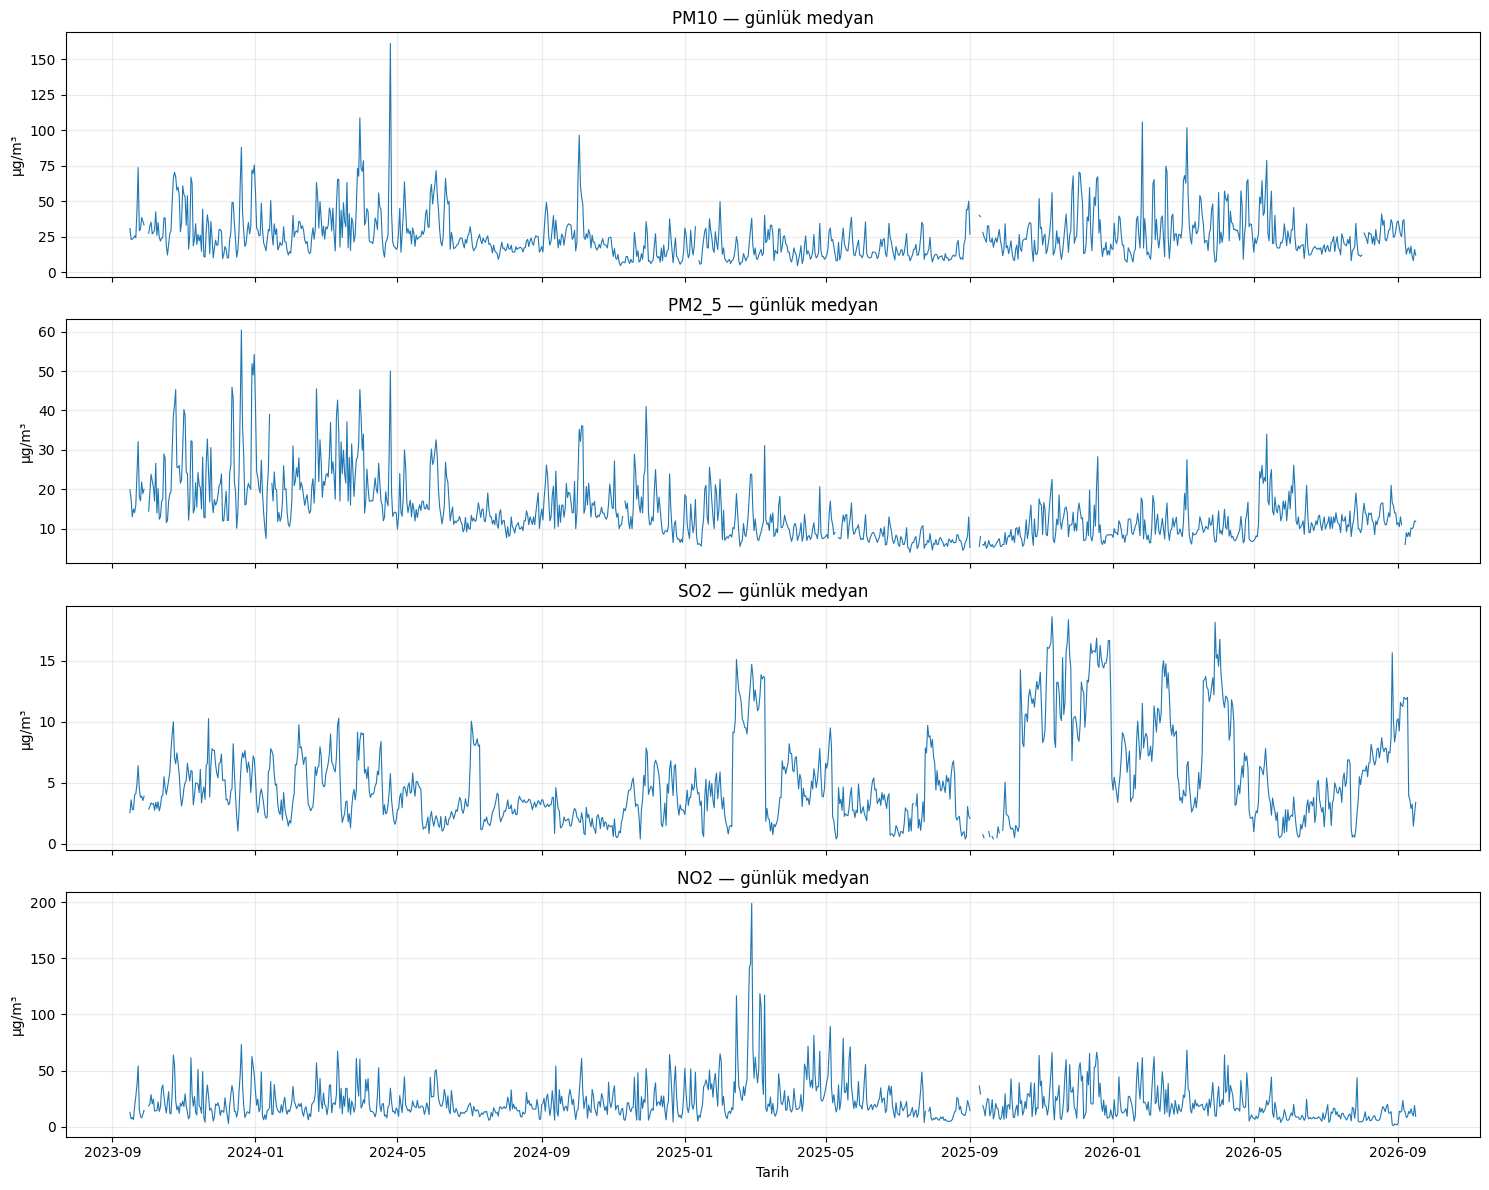

In [ ]:
gunluk_medyan = (
    eda_veri
    .set_index("tarih")[kirleticiler]
    .resample("D")
    .median()
)

fig, eksenler = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

for i, kirletici in enumerate(kirleticiler):
    eksenler[i].plot(
        gunluk_medyan.index,
        gunluk_medyan[kirletici],
        linewidth=0.8
    )
    eksenler[i].set_title(f"{kirletici} — günlük medyan")
    eksenler[i].set_ylabel("µg/m³")
    eksenler[i].grid(alpha=0.25)

plt.xlabel("Tarih")
plt.tight_layout()
plt.show()

In [ ]:
gunluk_sayi = (
    eda_veri.set_index("tarih")[kirleticiler]
    .resample("D")
    .count()
)

gunluk_ozet = pd.DataFrame({
    "Toplam gün": [len(gunluk_sayi)] * len(kirleticiler),
    "18 saatten az ölçülen gün": [
        (gunluk_sayi[k] < 18).sum() for k in kirleticiler
    ],
    "Hiç ölçülmeyen gün": [
        (gunluk_sayi[k] == 0).sum() for k in kirleticiler
    ]
}, index=kirleticiler)

display(gunluk_ozet)

# Dönem karşılaştırmaları için yeterli ölçümü olan günleri ayırıyoruz.
gunluk_medyan_yeterli = gunluk_medyan.where(gunluk_sayi >= 18)

print("Ölçüm sayısı yetersiz günlerden örnekler:")
display(gunluk_sayi[gunluk_sayi.lt(18).any(axis=1)].head(15))

,Toplam gün,18 saatten az ölçülen gün,Hiç ölçülmeyen gün
PM10,1097,38,14
PM2_5,1097,53,17
SO2,1097,71,21
NO2,1097,49,13


Ölçüm sayısı yetersiz günlerden örnekler:


,PM10,PM2_5,SO2,NO2
tarih,,,,
2023-09-19,13,13,14,14
2023-09-20,10,11,11,11
2023-09-28,16,16,16,16
2023-09-29,0,0,0,0
2023-09-30,0,0,0,0
2023-10-01,0,0,0,0
2023-10-02,10,10,12,12
2023-12-03,24,17,24,19
2024-01-12,21,16,23,24


In [ ]:
# Yeterli ölçümü olan günlerden aylık medyan oluştur
aylik_gun_sayisi = gunluk_medyan_yeterli.resample("MS").count()
aylik_medyan = gunluk_medyan_yeterli.resample("MS").median()

# Bir ayı göstermek için en az 20 geçerli gün şartı
aylik_medyan = aylik_medyan.where(aylik_gun_sayisi >= 20)

print("20 geçerli günden az verisi olan aylar:")
display(aylik_gun_sayisi[aylik_gun_sayisi.lt(20).any(axis=1)])

20 geçerli günden az verisi olan aylar:


,PM10,PM2_5,SO2,NO2
tarih,,,,
2023-09-01,10,10,10,10
2024-11-01,29,16,26,29
2025-09-01,17,17,0,18
2026-09-01,15,12,13,13


# EDA kapanışı — Arnavutköy

Veri kaynağı: Bakanlığın resmî SİM istasyon veri indirme sayfası: https://sim.csb.gov.tr/STN/STN_Report/StationDataDownloadNew

İndirme tarihi: **16 Ekim 2026**. Veri dönemi: 16 Eylül 2023 00:00:56–16 Eylül 2026 00:00:56. İstasyon: İstanbul–Arnavutköy. Birim: µg/m³.


18 saat/gün (%75) ve 20 geçerli gün/ay koşulları projeye özgü analiz tercihleridir; resmî standart olarak sunulmamıştır. Günlük medyanlar saatlik uçları özetler. Aylık değer, yeterli günlük medyanların medyanıdır. Uzun boşluklar doldurulmamıştır. 985 değerleri kesin hata değil, şüpheli ölçüm olarak yalnızca analiz kopyasında dışlanmıştır.


Not: Önceki notebook çıktıları korunmuştur. Eklenen grafik hücreleri Colab üzerinde çalıştırılmak üzere hazırlanmıştır; 985 duyarlılık hücresi kaynak Excel üzerinde yeniden çalıştırılarak çıktıları eklenmiştir.

,PM10,PM2_5,SO2,NO2
tarih,,,,
2023-09-01,10,10,10,10
2024-11-01,29,16,26,29
2025-09-01,17,17,0,18
2026-09-01,15,12,13,13


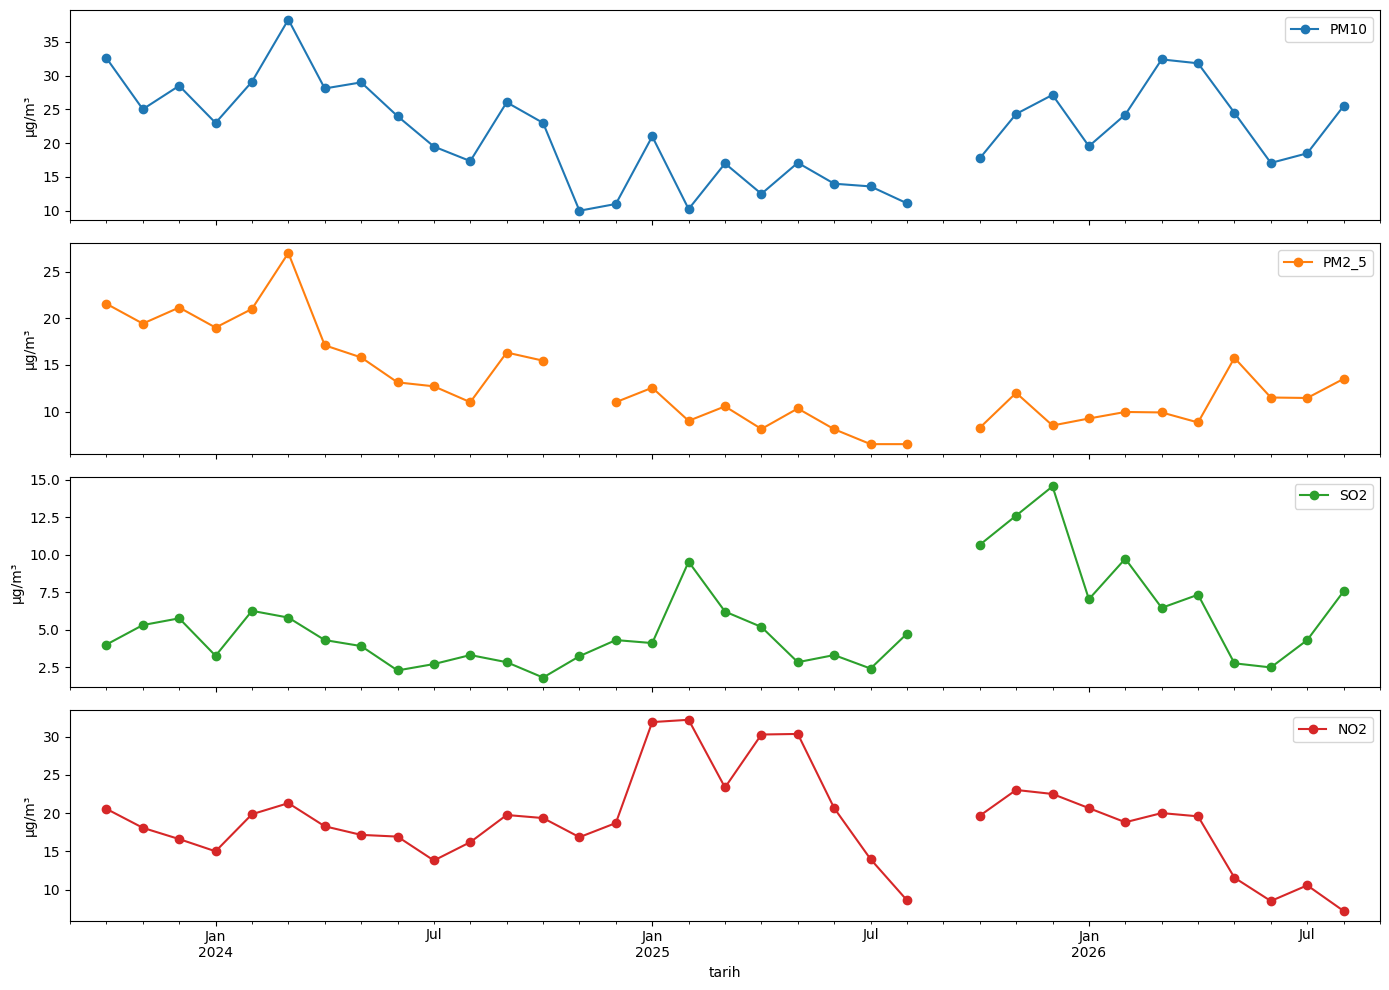

In [ ]:
kirleticiler = ["PM10", "PM2_5", "SO2", "NO2"]
saatlik = eda_veri.set_index("tarih")[kirleticiler].astype(float)
gunluk_sayi = saatlik.resample("D").count()
gunluk_medyan_yeterli = saatlik.resample("D").median().where(gunluk_sayi >= 18)
aylik_gun_sayisi = gunluk_medyan_yeterli.resample("MS").count()
aylik_medyan = gunluk_medyan_yeterli.resample("MS").median().where(aylik_gun_sayisi >= 20)
display(aylik_gun_sayisi[aylik_gun_sayisi.lt(20).any(axis=1)])
aylik_medyan.plot(subplots=True, figsize=(14,10), marker="o", ylabel="µg/m³")
plt.tight_layout(); plt.show()


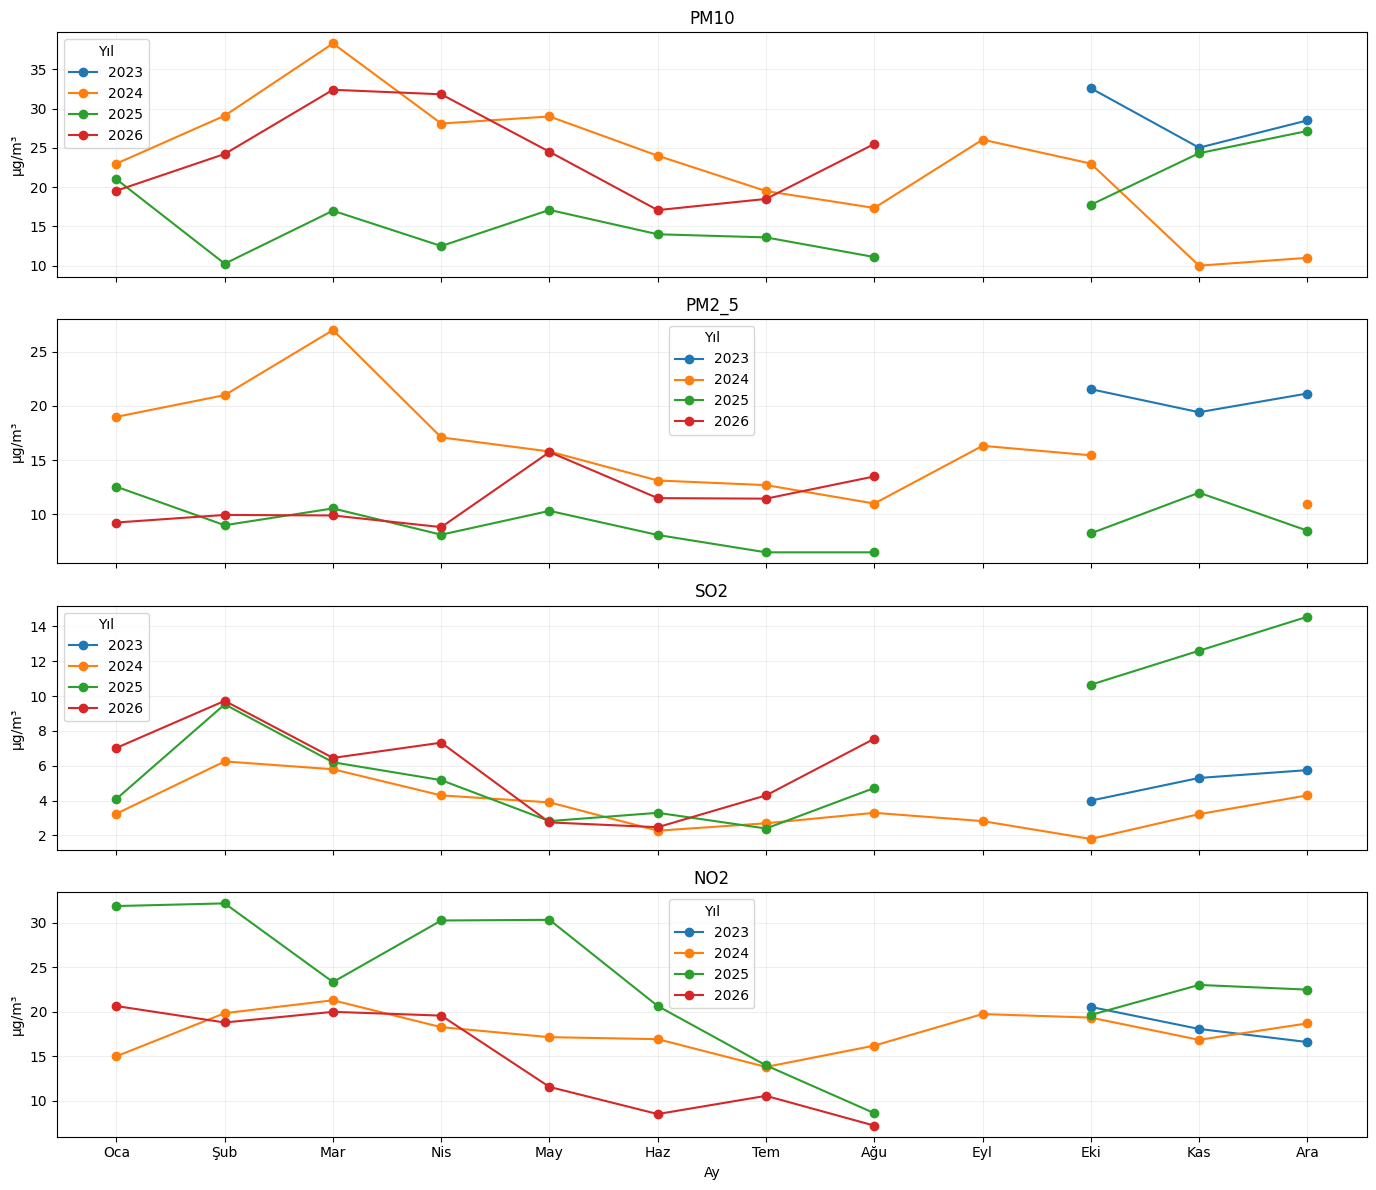

In [ ]:
ay_adlari = ["Oca","Şub","Mar","Nis","May","Haz","Tem","Ağu","Eyl","Eki","Kas","Ara"]
fig, axes = plt.subplots(4,1,figsize=(14,12),sharex=True)
for ax,k in zip(axes,kirleticiler):
    a=aylik_medyan[[k]].assign(Yıl=aylik_medyan.index.year,Ay=aylik_medyan.index.month)
    a.pivot(index="Ay",columns="Yıl",values=k).reindex(range(1,13)).plot(ax=ax,marker="o")
    ax.set_title(k); ax.set_ylabel("µg/m³"); ax.grid(alpha=.2)
axes[-1].set_xticks(range(1,13)); axes[-1].set_xticklabels(ay_adlari)
plt.tight_layout(); plt.show()


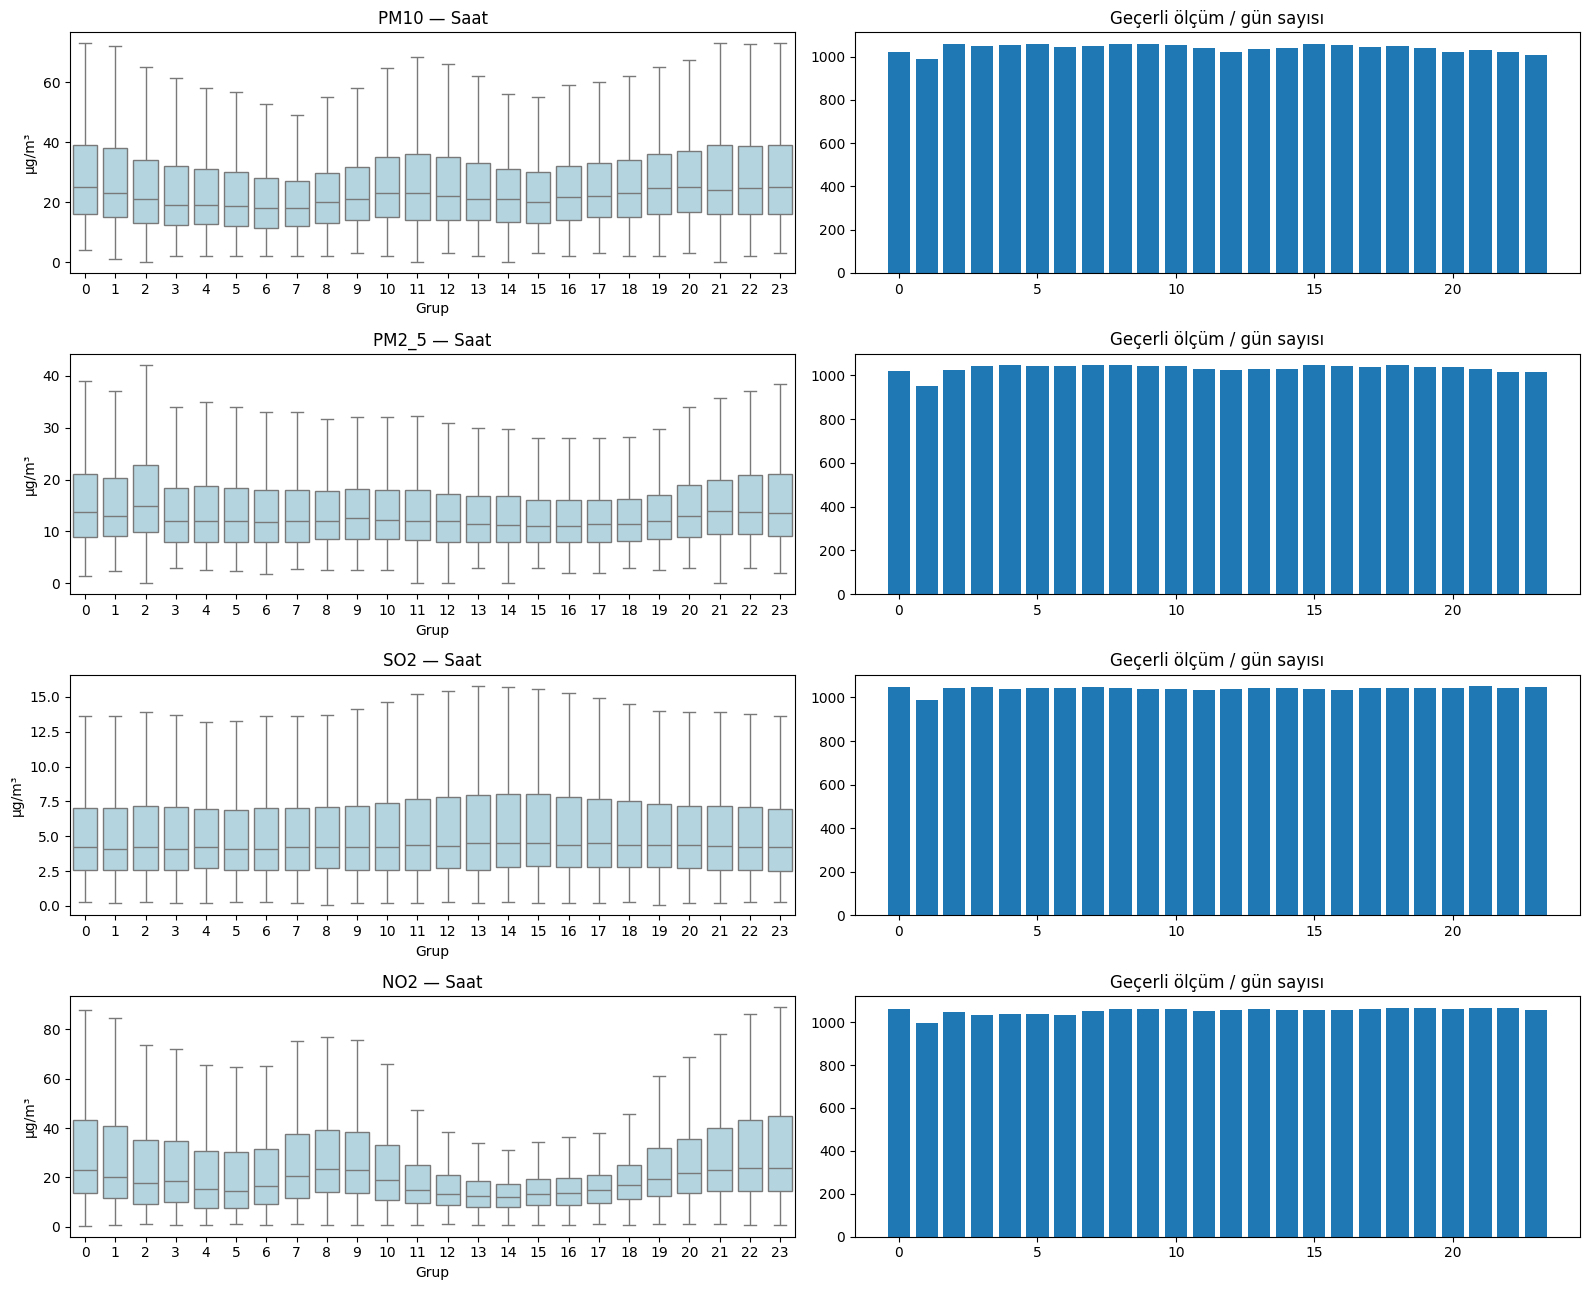

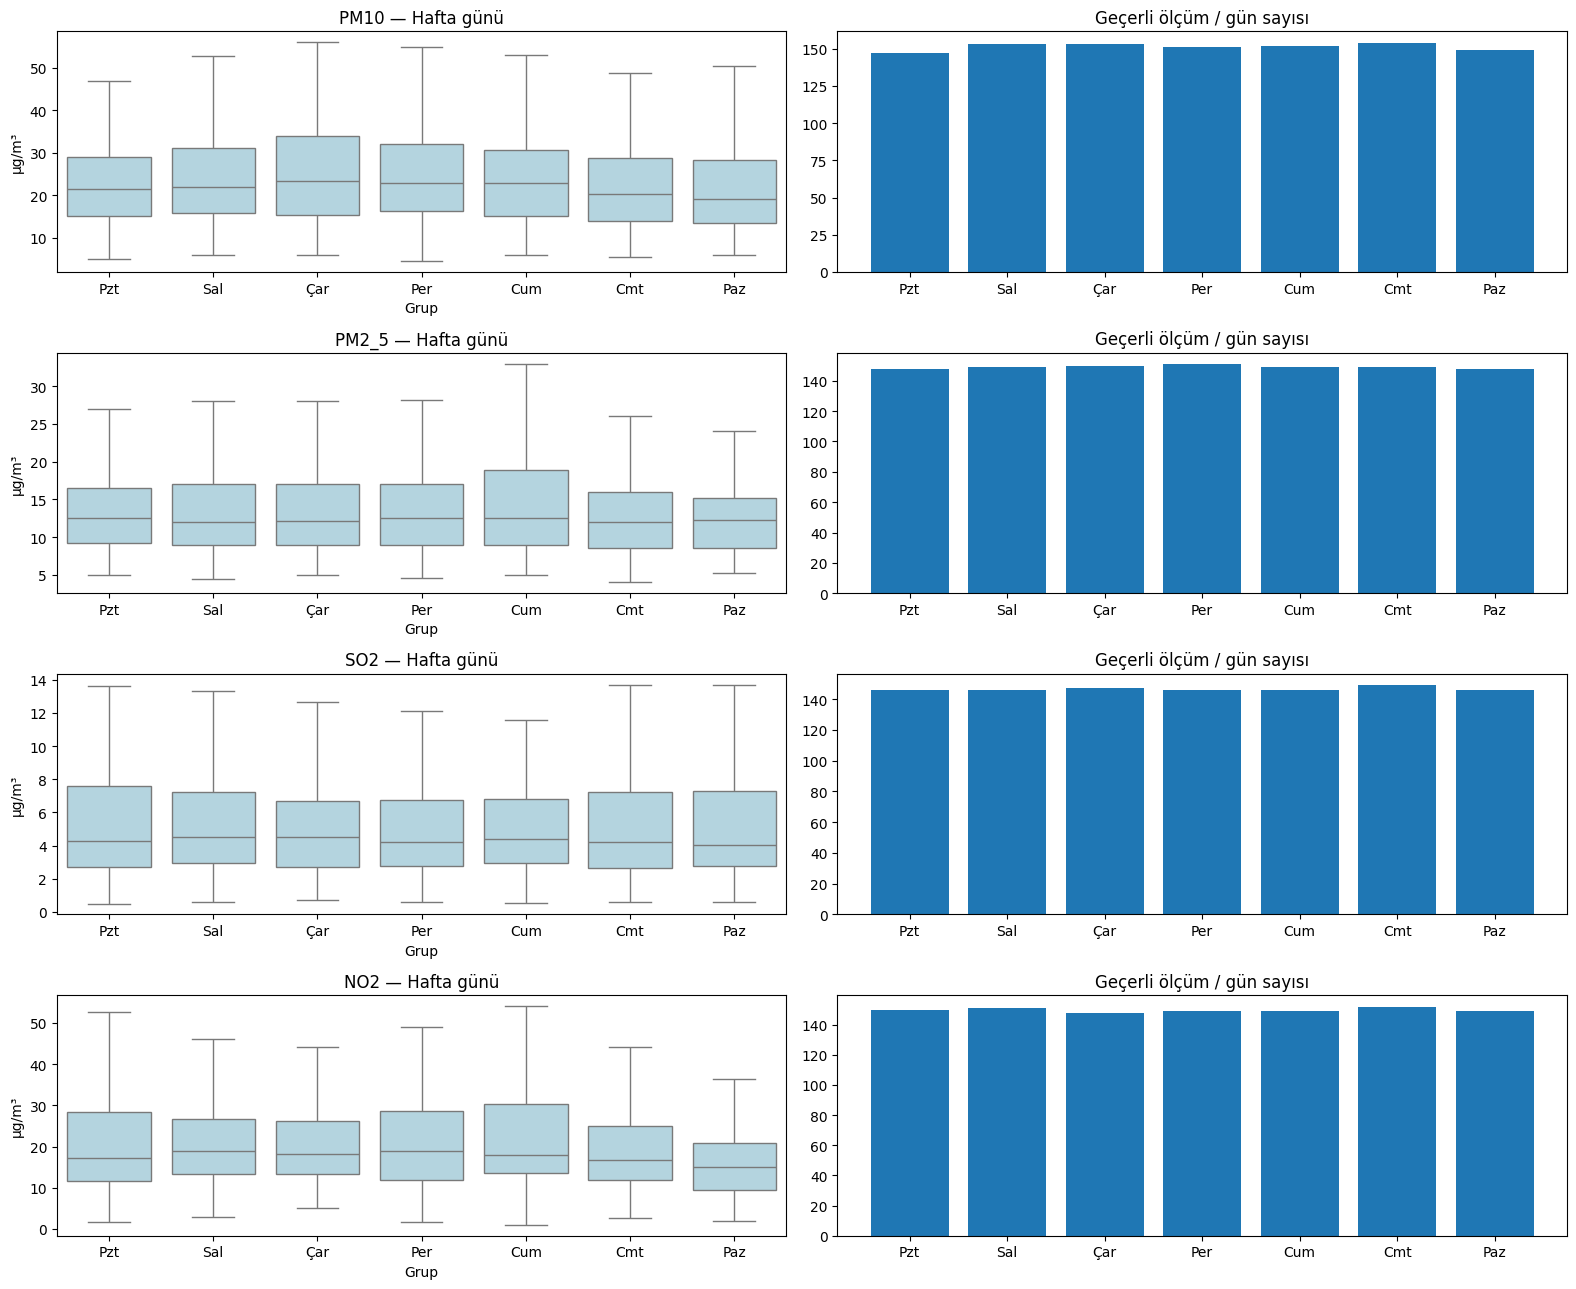

In [ ]:
for boyut,tablo,grup,etiketler in [
    ("Saat",saatlik,saatlik.index.hour,list(range(24))),
    ("Hafta günü",gunluk_medyan_yeterli,gunluk_medyan_yeterli.index.dayofweek,["Pzt","Sal","Çar","Per","Cum","Cmt","Paz"])]:
    a=tablo.copy(); a["Grup"]=grup
    sayilar=a.groupby("Grup")[kirleticiler].count()
    fig,axes=plt.subplots(4,2,figsize=(16,13))
    for i,k in enumerate(kirleticiler):
        sns.boxplot(data=a,x="Grup",y=k,showfliers=False,ax=axes[i,0],color="lightblue")
        axes[i,0].set_title(f"{k} — {boyut}");axes[i,0].set_ylabel("µg/m³")
        axes[i,0].set_xticks(range(len(etiketler)));axes[i,0].set_xticklabels(etiketler)
        axes[i,1].bar(etiketler,sayilar[k]);axes[i,1].set_title("Geçerli ölçüm / gün sayısı")
    plt.tight_layout();plt.show()


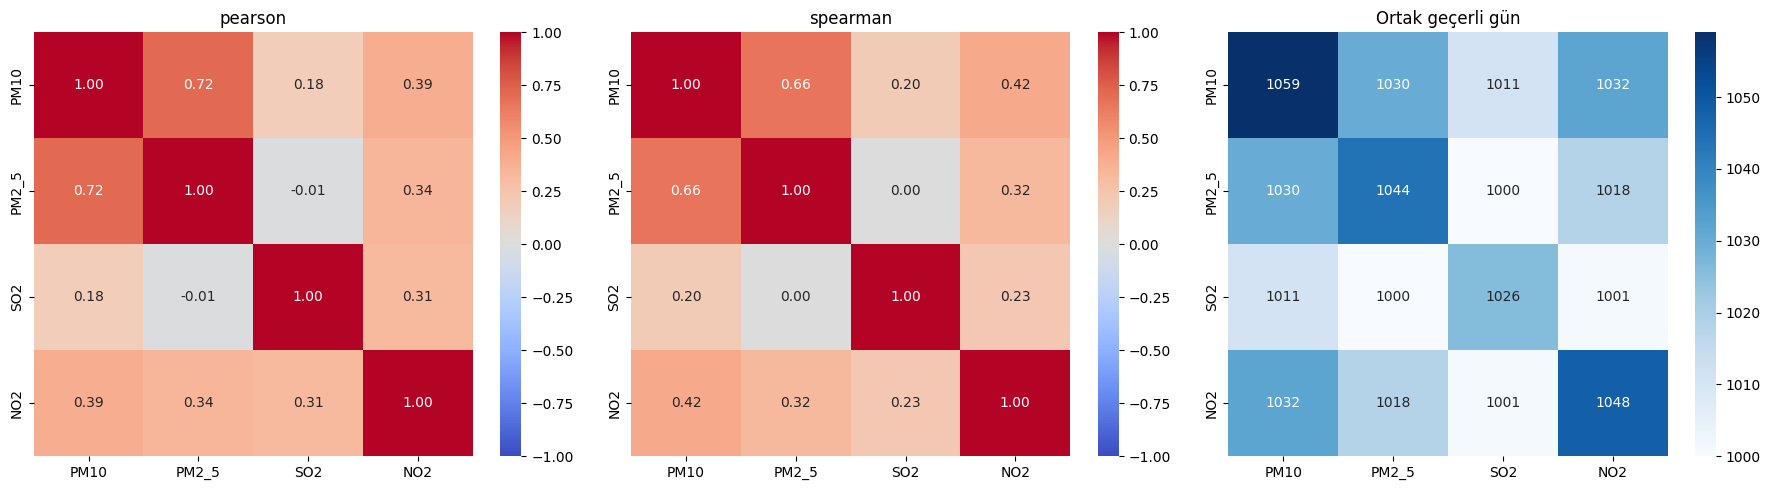

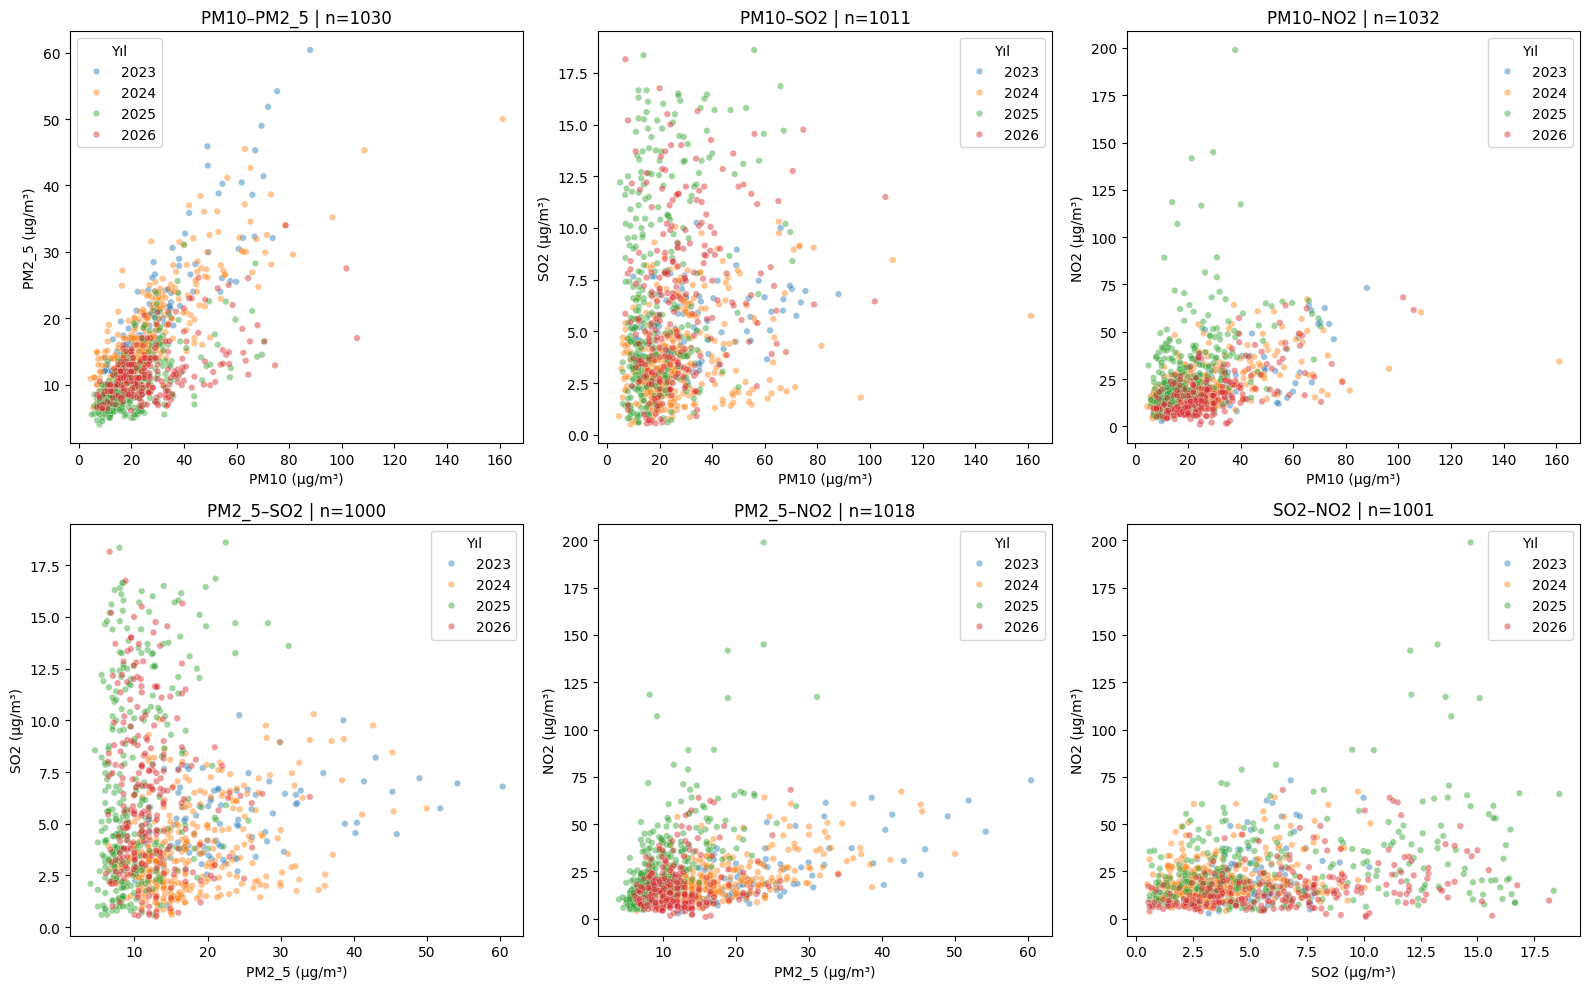

In [ ]:
korelasyon_verisi=gunluk_medyan_yeterli[kirleticiler].astype(float)
dolu=korelasyon_verisi.notna().astype(int)
fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,yontem in zip(axes[:2],["pearson","spearman"]):
    sns.heatmap(korelasyon_verisi.corr(method=yontem),annot=True,fmt=".2f",vmin=-1,vmax=1,cmap="coolwarm",ax=ax)
    ax.set_title(yontem)
sns.heatmap(dolu.T.dot(dolu),annot=True,fmt="d",cmap="Blues",ax=axes[2]);axes[2].set_title("Ortak geçerli gün")
plt.tight_layout();plt.show()
from itertools import combinations
fig,axes=plt.subplots(2,3,figsize=(16,10))
for ax,(x,y) in zip(axes.flat,combinations(kirleticiler,2)):
    a=korelasyon_verisi[[x,y]].dropna().copy();a["Yıl"]=a.index.year.astype(str)
    sns.scatterplot(data=a,x=x,y=y,hue="Yıl",alpha=.45,s=22,ax=ax)
    ax.set_title(f"{x}–{y} | n={len(a)}");ax.set_xlabel(x+" (µg/m³)");ax.set_ylabel(y+" (µg/m³)")
plt.tight_layout();plt.show()


In [ ]:
ozetler=[];donemler=[]
for x,y in combinations(kirleticiler,2):
    a=korelasyon_verisi[[x,y]].dropna().sort_index();q=a.quantile(.90)
    dates=a.index[a.ge(q).all(axis=1)]
    ozetler.append({"Çift":f"{x}–{y}","Ortak gün":len(a),"İlk P90":q[x],"İkinci P90":q[y],"Birlikte yüksek gün":len(dates),"Yüzde":100*len(dates)/len(a)})
    if len(dates):
        b=pd.DataFrame({"Tarih":dates});b["Grup"]=b.Tarih.diff().ne(pd.Timedelta(days=1)).cumsum()
        for _,g in b.groupby("Grup"):
            donemler.append({"Çift":f"{x}–{y}","Başlangıç":g.Tarih.min(),"Bitiş":g.Tarih.max(),"Ardışık gün":len(g)})
display(pd.DataFrame(ozetler).round(2))
display(pd.DataFrame(donemler).sort_values(["Çift","Ardışık gün","Başlangıç"],ascending=[True,False,True]).groupby("Çift").head(3))


,Çift,Ortak gün,İlk P90,İkinci P90,Birlikte yüksek gün,Yüzde
0,PM10–PM2_5,1030,45.98,24.00,62,6.02
1,PM10–SO2,1011,46.55,11.50,17,1.68
2,PM10–NO2,1032,45.91,41.79,43,4.17
3,PM2_5–SO2,1000,24.00,11.41,2,0.20
4,PM2_5–NO2,1018,24.00,41.72,31,3.05
5,SO2–NO2,1001,11.35,42.15,29,2.90


,Çift,Başlangıç,Bitiş,Ardışık gün
60,PM10–NO2,2025-12-16,2025-12-19,4
42,PM10–NO2,2023-12-29,2023-12-31,3
39,PM10–NO2,2023-10-23,2023-10-24,2
1,PM10–PM2_5,2023-10-22,2023-10-28,7
14,PM10–PM2_5,2024-03-27,2024-04-02,7
18,PM10–PM2_5,2024-05-29,2024-06-04,7
32,PM10–SO2,2025-12-16,2025-12-19,4
37,PM10–SO2,2026-04-07,2026-04-09,3
30,PM10–SO2,2025-12-05,2025-12-06,2
76,PM2_5–NO2,2023-12-29,2023-12-31,3


## 985 dahil–hariç duyarlılık kontrolü
Aynı işlemler ham ve analiz verisinde tekrarlanır. Bu kontrol 985 değerlerinin hatalı olduğunu kanıtlamaz; dışlama kararının sonuçlara etkisini ölçer.

In [ ]:
def ozetle(df):
    s=df.set_index("tarih")[kirleticiler].astype(float)
    n=s.resample("D").count()
    d=s.resample("D").median().where(n>=18)
    an=d.resample("MS").count()
    return d, d.resample("MS").median().where(an>=20), an

dahil_gun,dahil_ay,dahil_sayi=ozetle(veri)
haric_gun,haric_ay,haric_sayi=ozetle(eda_veri)
sonuclar=[]
for k in kirleticiler:
    fark=(haric_gun[k]-dahil_gun[k]).abs()
    ay_fark=(haric_ay[k]-dahil_ay[k]).abs()
    sonuclar.append({"Kirletici":k,"Ortalama dahil":veri[k].mean(),"Ortalama hariç":eda_veri[k].mean(),"Medyan dahil":veri[k].median(),"Medyan hariç":eda_veri[k].median(),"Değişen günlük medyan":int((fark>1e-9).sum()),"En büyük günlük fark":fark.max(),"Değişen aylık medyan":int((ay_fark>1e-9).sum()),"Gün yeterliliği değişen":int(dahil_gun[k].notna().ne(haric_gun[k].notna()).sum()),"Ay yeterliliği değişen":int(dahil_sayi[k].ge(20).ne(haric_sayi[k].ge(20)).sum())})
display(pd.DataFrame(sonuclar).round(4))
for method in ["pearson","spearman"]:
    fark=haric_gun.corr(method=method)-dahil_gun.corr(method=method)
    print(method,"— günlük korelasyonlarda en büyük mutlak değişim:",fark.abs().max().max())


,Kirletici,Ortalama dahil,Ortalama hariç,Medyan dahil,Medyan hariç,Değişen günlük medyan,En büyük günlük fark,Değişen aylık medyan,Gün yeterliliği değişen,Ay yeterliliği değişen
0,PM10,27.4626,27.3475,21.9,21.9,1,0.15,0,0,0
1,PM2_5,15.1177,14.9611,12.1,12.1,0,0.00,0,0,0
2,SO2,5.5040,5.5040,4.3,4.3,0,0.00,0,0,0
3,NO2,24.2742,24.2742,17.3,17.3,0,0.00,0,0,0


pearson — günlük korelasyonlarda en büyük mutlak değişim: 7.760018258057277e-06
spearman — günlük korelasyonlarda en büyük mutlak değişim: 4.329437409633652e-06


# Arnavutköy hava kalitesi — EDA kapanış raporu

## Kaynak ve kapsam
Veri kaynağı: Bakanlığın resmî SİM istasyon veri indirme sayfası, https://sim.csb.gov.tr/STN/STN_Report/StationDataDownloadNew . Kullanıcının bildirdiği indirme tarihi: **16 Ekim 2026**.

İstanbul–Arnavutköy istasyonunda PM10, PM2.5, SO2 ve NO2; 16 Eylül 2023 00:00:56–16 Eylül 2026 00:00:56; 26.305 saatlik kayıt; 1.097 takvim günü; birim µg/m³. Saatler kaynak dosyadaki biçimiyle kullanılmıştır. Kaynak dosyanın saat dilimi ayrıca doğrulanmamıştır.

## Yöntem
İki başlık satırı ayrılmış, tarih ve sayısal dönüşümler yapılmış, kayıtlar sıralanmıştır. Tekrarlı/geçersiz tarih ve saatlik çizelgede atlanan kayıt bulunmamıştır. Ham eksik oranları sırasıyla %5,13, %5,80, %5,04 ve %3,93'tür. Uzun boşluklar yapay örüntü oluşturmamak için doldurulmamıştır.

PM10'da üç, PM2.5'te dört adet 985 ölçümü şüpheli kabul edilerek analiz kopyasında eksik yapılmıştır. Kesin hata oldukları doğrulanmamıştır; ham veri korunmuştur. Diğer yüksek değerler otomatik çıkarılmamıştır. PM2.5>PM10 kayıtları kalite kontrol bulgusudur; kaynak/cihaz bilgisi olmadan otomatik silinmemiştir. Eski tanı hücrelerindeki cihaz arızası, bakım veya hata koduna ilişkin açıklamalar doğrulanmış nedenler değildir. 25 gözlemli merkezli hareketli pencere yalnızca EDA tanısıdır; geleceği kullandığı için tahmin girdisi olarak doğrudan kullanılmamalıdır.

Günlük medyan için en az 18 ölçüm (%75), aylık karşılaştırma için en az 20 geçerli gün aranmıştır. Bunlar proje tercihleridir, resmî standart değildir; eşik duyarlılığı ayrıca test edilmemiştir. Aylık değer yeterli günlük medyanların medyanıdır. Günlük yetersiz günler PM10/PM2.5/SO2/NO2 sırasıyla 38/53/71/49; hiç ölçülmeyen günler 14/17/21/13'tür.

Eylül 2023 ve Eylül 2026 kısmi aylardır. Kasım 2024 PM2.5 ve Eylül 2025 dört kirletici için aylık yetersizdir. Geçerli ay sayıları sırasıyla 34/33/34/34'tür. Aylık maske, günlük korelasyonlara uygulanmamıştır: bu analizlerde her çiftin yeterli ortak günleri kullanılır.

## Bulgular
Dağılımlar sağa çarpıktır: az sayıda yüksek ölçüm sağ kuyruğu oluşturur. PM10'da 2024 ve 2026 ilkbahar yükselişleri aynı büyüklükte 2025'te tekrarlanmamıştır. PM2.5'te 2024 ilk ayları yüksektir. SO2 Ekim–Aralık 2025'te diğer yılların aynı aylarından yüksektir. NO2 özellikle 2025/2026 yazına doğru düşer. Kısmi yıllar ve yıllar arası farklar nedeniyle kesin mevsimsellik iddiası kurulmamıştır.

NO2 sabah ve akşam–gece yüksek, öğle–öğleden sonra düşüktür. PM10 sabah erken saatlerde görece düşük, akşam–gece yüksektir. PM2.5 saatlik farkları sınırlı, SO2 medyanları benzerdir. Saatlik sayılar genellikle yakındır; 01.00'de azalma vardır. Saat dilimi doğrulanmadan bu saatler yerel saat olarak kesin yorumlanmamalıdır.

Hafta günü dağılımları büyük ölçüde örtüşür; PM10 ve NO2 Pazar medyanları görece düşüktür. Sayılar dengelidir; anlamlılık testi yapılmamıştır. Grafiklerde gizlenen uç noktalar veriden silinmemiştir.

PM10–PM2.5 Pearson 0,72/Spearman 0,66 ile en belirgin ilişkiyi gösterir (1.030 ortak gün). PM10–NO2 0,39/0,42; PM2.5–NO2 0,34/0,32; SO2–NO2 0,31/0,23; PM10–SO2 0,18/0,20; PM2.5–SO2 −0,01/0,00'dır. Sıfıra yakın korelasyon bağımsızlık kanıtı değildir. Ortak mevsim ve yıllar arası farklar katsayıları etkileyebilir; günler bağımsız örnekler değildir.

Çiftin ortak günlerinde hesaplanan ayrı P90 eşiklerine göre birlikte yüksek günler: PM10–PM2.5 62 (%6,02), PM10–NO2 43 (%4,17), PM2.5–NO2 31 (%3,05), SO2–NO2 29 (%2,90), PM10–SO2 17 (%1,68), PM2.5–SO2 2 (%0,20). Bunlar sağlık/mevzuat aşımı veya aynı saatte yükseliş anlamına gelmez. PM10–PM2.5 için 22–28 Ekim 2023, 27 Mart–2 Nisan 2024 ve 29 Mayıs–4 Haziran 2024 dönemleri yedişer gündür. 16–19 Aralık 2025'te PM10, SO2 ve NO2 ilgili çift eşiklerine göre birlikte yüksektir. Eksik veya koşulu sağlamayan günler dönemleri böler.

## 985 duyarlılık kontrolü — yeniden hesaplanan sonuçlar
| Ölçüt | 985 dahil | 985 hariç |
|---|---:|---:|
| PM10 saatlik ortalama | 27,4626 | 27,3475 |
| PM2.5 saatlik ortalama | 15,1177 | 14,9611 |
| PM10 saatlik medyan | 21,9 | 21,9 |
| PM2.5 saatlik medyan | 12,1 | 12,1 |

Birim µg/m³. PM10 ortalaması yaklaşık %0,42, PM2.5 ortalaması %1,04 azalır. SO2/NO2 değişmez. Yeterli günlük medyanlardan yalnızca 16 Eylül 2023 PM10 değeri 30,85'ten 30,70'e değişir (0,15). PM2.5'in 985 içeren günü her iki senaryoda da günlük yetersizdir. Günlük/aylık yeterlilik kararları ve karşılaştırmaya alınan aylık medyanların tamamı değişmez. Günlük Pearson/Spearman katsayılarındaki en büyük mutlak fark 0,00001'den küçüktür; iki ondalıklı yorumlar değişmez.

Sonuç: incelenen aylık medyanlar ve günlük korelasyon bulguları bu yedi değerin dışlanmasına çok az duyarlıdır. Bu, ölçümlerin kesin hatalı olduğu anlamına gelmez. Saatlik uçlar ve ortalamalar için dışlama kararı yine açıklanmalıdır. P90 olay tablosu için ayrıca dahil–hariç karşılaştırma yapılmamıştır.

## EDA durumu ve ekip devri
Planlanan beş EDA adımı ve 985 son kontrolü tamamlanmıştır. Bulgular betimleyicidir; neden-sonuç çıkarımı yapılmamıştır. Meteoroloji, bakım/kalibrasyon bilgisi ve şüpheli ölçümlerin doğrulaması mevcut değildir. Tek istasyon tüm İstanbul'u temsil etmez.

Yöntem seçimi, ilk model denemesi ve teslim hazırlığı diğer ekip üyelerinin kapsamındadır. Ekip; tahmin hedefini/ufkunu, kronolojik değerlendirme dönemlerini, başlangıç tahminini ve metriklerini belirlemelidir. Bütün veri üzerinde EDA yapılmış olduğundan, gelecekte ayrılacak test dönemi tamamen hiç görülmemiş bir dönem olarak sunulmamalıdır. Öğrenilen doldurma/ölçekleme işlemleri yalnızca eğitim verisine göre kurulmalıdır.


Sorulması muhtemel sorular:
1. Uzun boşluklara neden değer atanmadı?
Birkaç günlük eksikliği doldurmak, gerçekte ölçülmemiş bir kirlilik örüntüsü oluşturabilir. Sonuçları yanıltmamak için EDA’da bu boşlukları koruduk.
2. 985 değeri neden analiz kopyasında eksik değere çevrildi?
Aynı çok yüksek değerin tekrarlanması ve çevresindeki ölçümlerden belirgin biçimde ayrılması şüphe oluşturdu. Kesin hata olduğunu doğrulamadığımız için ham veriyi koruduk; analizde etkisini sınırlamak için bu ölçümleri geçici olarak dışladık.
3. Neden en az 18 saatlik ölçüm arandı?
18 saat, bir günün %75’idir. Günlük medyanın yalnızca birkaç saate dayanmasını önlemek için bu eşiği seçtik. Bu, bizim analiz tercihimiz; tek başına günün tamamen temsil edildiğini garanti etmez.
4. Neden ayda en az 20 geçerli gün arandı?
Aylık sonucu birkaç günün belirlemesini önlemek ve ayın önemli bir bölümünü temsil etmek için seçtik. Bu da projeye özgü bir tercih; resmî bir standart olarak kullanmadık. Burada geçerli sayılan birim aydır; ayın içinde en az 20 geçerli gün aranır.
5. “Dağılımlar sağa çarpık” ne demek?
Ölçümlerin çoğu düşük–orta seviyelerde, az sayıdaki ölçüm ise çok yüksek demektir. Histogramın yüksek değerlere uzanan sağ kuyruğu vardır. Bu yüzden ortalama, medyandan daha fazla etkilenebilir.
6. Neden Pearson ve Spearman hesaplandı?
Pearson, değerlerin doğrusal olarak birlikte değişmesini ölçer. Spearman, değerlerin sıralamalarının birlikte değişmesini ölçer ve uç değerlerden genellikle daha az etkilenir. İkisini karşılaştırarak ilişkinin farklı ölçümlerde tutarlı olup olmadığını kontrol ettik.